# Recommendation detection: Frozen ParsBERT grid search

Run `prepare_data.ipynb` first. Read its shared train/test rows and validation folds, apply the original light normalization, and use ParsBERT as a fixed encoder. Search classifiers on training embeddings and evaluate the selected classifier on the reserved test rows. If SVC wins, refit the same configuration with probability estimates, inspect its test results, and save the encoder, tokenizer, and fitted classifier in `output models`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import string
import hazm
import matplotlib.pyplot as plt

RANDOM_STATE = 18
N_JOBS = 2
LABELS = {"not_recommended": 0, "recommended": 1}
LABEL_NAMES = {value: key for key, value in LABELS.items()}
PROJECT_ROOT = next(
    (root for root in (Path.cwd(), *Path.cwd().parents)
     if (root / "data" / "digikala-comments.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from the project root or one of its subdirectories.")
train_path = PROJECT_ROOT / "data" / "train.parquet"
test_path = PROJECT_ROOT / "data" / "test.parquet"
if not train_path.is_file() or not test_path.is_file():
    raise FileNotFoundError("Run prepare_data.ipynb to create data/train.parquet and data/test.parquet.")

train_data = pd.read_parquet(train_path, engine="pyarrow").reset_index(drop=True)
test_data = pd.read_parquet(test_path, engine="pyarrow").reset_index(drop=True)
required = {"source_row", "body", "processed_body", "recommendation_status"}
if not required.union({"fold"}).issubset(train_data.columns) or not required.issubset(test_data.columns):
    raise ValueError("Prepared data columns are missing. Run prepare_data.ipynb again.")
for frame in (train_data, test_data):
    assert frame["source_row"].is_unique
    assert not frame[list(required)].isna().any().any()
    assert set(frame["recommendation_status"]) == set(LABELS.values())
assert set(train_data["source_row"]).isdisjoint(test_data["source_row"])
assert set(train_data["processed_body"]).isdisjoint(test_data["processed_body"])

y_train = train_data["recommendation_status"]
y_test = test_data["recommendation_status"]
fold_ids = train_data["fold"]
assert fold_ids.notna().all() and fold_ids.ge(0).all()
cv = [
    (np.flatnonzero(fold_ids.to_numpy() != fold),
     np.flatnonzero(fold_ids.to_numpy() == fold))
    for fold in sorted(fold_ids.unique())
]
assert len(cv) >= 2
for train_positions, valid_positions in cv:
    assert set(y_train.iloc[train_positions]) == set(LABELS.values())
    assert set(y_train.iloc[valid_positions]) == set(LABELS.values())
print("Train:", len(train_data), "| Test:", len(test_data), "| Shared CV folds:", len(cv))


Train: 7995 | Test: 1999 | Shared CV folds: 5


## Shared light normalization

Use the original comments from Parquet and the same normalization as the original ParsBERT experiment. Preserve the stored row order, labels, and validation folds.


In [2]:
normalizer = hazm.Normalizer()


def remove_chars(text, chars):
    for char in chars:
        text = text.replace(char, " ")
    return text


def preprocess_light(text):
    if not isinstance(text, str):
        return None
    text = remove_chars(text.lower(), string.punctuation + "؟،")
    text = normalizer.normalize(text).replace("آ", "ا")
    text = remove_chars(text, "۰۱۲۳۴۵۶۷۸۹")
    return " ".join(text.split()) or None


X_train_light = train_data["body"].apply(preprocess_light)
X_test_light = test_data["body"].apply(preprocess_light)
if X_train_light.isna().any() or X_test_light.isna().any():
    raise ValueError("An empty comment appeared after light normalization.")
assert X_train_light.index.equals(y_train.index)
assert X_test_light.index.equals(y_test.index)


## 6. Frozen ParsBERT

Use [`HooshvareLab/bert-base-parsbert-uncased`](https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased) as a fixed encoder; this section needs `torch` and `transformers`. Mean-pool token vectors while excluding padding, and truncate at 128 tokens. Encode training comments once, then compare LogisticRegression, LinearSVC, RidgeClassifier, and RBF SVC on the same five folds. The encoder is not fine-tuned.


In [3]:
import numpy as np
import torch
from transformers import AutoModel, AutoTokenizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from joblib import parallel_config

BERT_MODEL_ID = "HooshvareLab/bert-base-parsbert-uncased"
BERT_MAX_LENGTH = 128
BERT_BATCH_SIZE = 16 if torch.cuda.is_available() else 8
bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_ID)
bert_encoder = AutoModel.from_pretrained(BERT_MODEL_ID).to(bert_device)
bert_encoder.eval()


@torch.inference_mode()
def encode_comments_bert(texts):
    vectors = []
    texts = texts.tolist()
    for start in range(0, len(texts), BERT_BATCH_SIZE):
        batch = texts[start:start + BERT_BATCH_SIZE]
        tokens = bert_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=BERT_MAX_LENGTH,
            return_tensors="pt",
        )
        tokens = {name: value.to(bert_device) for name, value in tokens.items()}
        token_vectors = bert_encoder(**tokens).last_hidden_state
        attention_mask = tokens["attention_mask"].unsqueeze(-1)
        pooled = (token_vectors * attention_mask).sum(dim=1) / attention_mask.sum(dim=1).clamp(min=1)
        vectors.append(pooled.cpu().numpy())
        if (start // BERT_BATCH_SIZE + 1) % 50 == 0 or start + len(batch) == len(texts):
            print(f"Encoded {start + len(batch)}/{len(texts)} comments")
    return np.vstack(vectors)


X_train_bert = encode_comments_bert(X_train_light)
print("ParsBERT device:", bert_device)
print("Train embeddings:", X_train_bert.shape)


f:\Roham\projects\Web\Django\vazheh-kav\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 26680693-4288-417b-8a52-2d2f0043f469)')' thrown while requesting HEAD https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased/resolve/main/tokenizer_config.json
Retrying in 1s [Retry 1/5].
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: fcc6999c-a239-4c47-bc12-fdf0943fd01b)')' thrown while requesting HEAD https://huggingface.co/HooshvareLab/bert-base-parsbert-uncased/resolve/main/tokenizer_config.json
Retrying in 2s [Retry 2/5].
'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. 

Encoded 800/7995 comments
Encoded 1600/7995 comments
Encoded 2400/7995 comments
Encoded 3200/7995 comments
Encoded 4000/7995 comments
Encoded 4800/7995 comments
Encoded 5600/7995 comments
Encoded 6400/7995 comments
Encoded 7200/7995 comments
Encoded 7995/7995 comments
ParsBERT device: cuda
Train embeddings: (7995, 768)


In [4]:
from sklearn.preprocessing import Normalizer
from sklearn.svm import SVC

bert_pipeline = Pipeline([
    ("normalize", Normalizer()),
    ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
bert_param_grid = [
    {
        "model": [LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [LinearSVC(max_iter=5000, random_state=RANDOM_STATE)],
        "model__C": [0.1, 1.0, 10.0],
    },
    {
        "model": [RidgeClassifier()],
        "model__alpha": [0.1, 1.0, 10.0],
    },
    {
        "model": [SVC(kernel="rbf", gamma="scale")],
        "model__C": [1.0, 10.0],
    },
]
bert_grid = GridSearchCV(
    estimator=bert_pipeline,
    param_grid=bert_param_grid,
    scoring={"macro_f1": "f1_macro", "accuracy": "accuracy"},
    refit="macro_f1",
    cv=cv,
    n_jobs=N_JOBS,
    pre_dispatch=N_JOBS,
    error_score="raise",
    return_train_score=True,
)
with parallel_config(backend="loky", inner_max_num_threads=1):
    bert_grid.fit(X_train_bert, y_train)

bert_cv_results = pd.DataFrame(bert_grid.cv_results_)
bert_cv_results["model_name"] = bert_cv_results["param_model"].map(
    lambda model: type(model).__name__
)
bert_cv_results = bert_cv_results.sort_values("rank_test_macro_f1", kind="stable")
display(bert_cv_results[[
    "model_name", "mean_test_macro_f1", "std_test_macro_f1",
    "mean_test_accuracy", "mean_train_macro_f1", "params",
]])
print("Best ParsBERT training CV macro-F1:", bert_grid.best_score_)
print("Best classifier parameters:", bert_grid.best_params_)


,model_name,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_train_macro_f1,params
9,SVC,0.876123,0.004574,0.876173,0.908069,"{'model': SVC(), 'model__C': 1.0}"
10,SVC,0.874787,0.005585,0.874797,0.985241,"{'model': SVC(), 'model__C': 10.0}"
4,LinearSVC,0.873003,0.007242,0.873046,0.894009,"{'model': LinearSVC(max_iter=5000, random_stat..."
7,RidgeClassifier,0.871351,0.007679,0.871420,0.888357,"{'model': RidgeClassifier(), 'model__alpha': 1.0}"
2,LogisticRegression,0.870629,0.006989,0.870669,0.889979,"{'model': LogisticRegression(max_iter=2000, ra..."
3,LinearSVC,0.869698,0.006355,0.869794,0.878545,"{'model': LinearSVC(max_iter=5000, random_stat..."
6,RidgeClassifier,0.869005,0.008392,0.869043,0.901636,"{'model': RidgeClassifier(), 'model__alpha': 0.1}"
1,LogisticRegression,0.868467,0.004854,0.868543,0.877719,"{'model': LogisticRegression(max_iter=2000, ra..."
5,LinearSVC,0.867134,0.004704,0.867167,0.911564,"{'model': LinearSVC(max_iter=5000, random_stat..."
8,RidgeClassifier,0.865659,0.006990,0.865791,0.871556,"{'model': RidgeClassifier(), 'model__alpha': 1..."


Best ParsBERT training CV macro-F1: 0.8761228352011395
Best classifier parameters: {'model': SVC(), 'model__C': 1.0}


Encoded 800/1999 comments
Encoded 1600/1999 comments
Encoded 1999/1999 comments
Frozen ParsBERT test classification report:
                 precision    recall  f1-score   support

not_recommended      0.887     0.908     0.897      1000
    recommended      0.906     0.884     0.895       999

       accuracy                          0.896      1999
      macro avg      0.896     0.896     0.896      1999
   weighted avg      0.896     0.896     0.896      1999



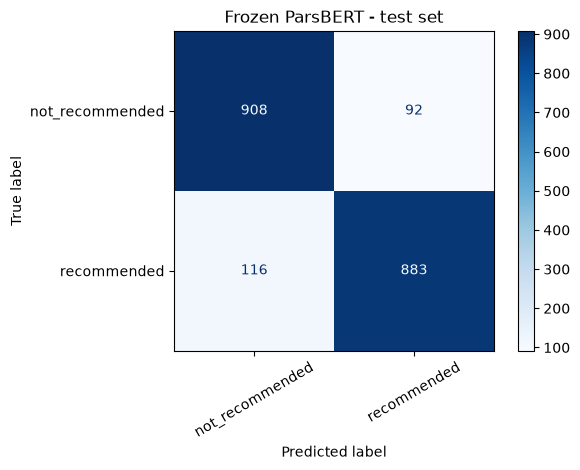

In [5]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Evaluate the classifier selected by training CV on the same test rows.
X_test_bert = encode_comments_bert(X_test_light)
bert_test_pred = bert_grid.predict(X_test_bert)

print("Frozen ParsBERT test classification report:")
print(classification_report(
    y_test, bert_test_pred,
    labels=list(LABEL_NAMES),
    target_names=[LABEL_NAMES[label] for label in LABEL_NAMES],
    digits=3,
    zero_division=0,
))
ConfusionMatrixDisplay.from_predictions(
    y_test, bert_test_pred,
    labels=list(LABEL_NAMES),
    display_labels=[LABEL_NAMES[label] for label in LABEL_NAMES],
    cmap="Blues", values_format="d", xticks_rotation=30,
)
plt.title("Frozen ParsBERT - test set")
plt.tight_layout()
plt.show()


### Probability estimates for the selected SVC

Refit only the winning SVC with `probability=True` on all training embeddings. This keeps the grid search fast. Compare its test predictions with the original SVC and report the probability Brier score.


In [6]:
from sklearn.base import clone

if not isinstance(bert_grid.best_estimator_.named_steps["model"], SVC):
    raise ValueError("This probability step expects SVC to win the ParsBERT grid search.")

probabilistic_bert_pipeline = clone(bert_grid.best_estimator_).set_params(
    model__probability=True,
    model__random_state=RANDOM_STATE,
)
with parallel_config(backend="loky", inner_max_num_threads=1):
    probabilistic_bert_pipeline.fit(X_train_bert, y_train)

print("Selected SVC with probability estimates:", probabilistic_bert_pipeline.named_steps["model"])
print("Classes:", probabilistic_bert_pipeline.classes_)


f:\Roham\projects\Web\Django\vazheh-kav\venv\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Selected SVC with probability estimates: SVC(probability=True, random_state=18)
Classes: [0 1]


In [7]:
from sklearn.metrics import accuracy_score, brier_score_loss, f1_score

probabilistic_bert_pred = probabilistic_bert_pipeline.predict(X_test_bert)
positive_label = LABELS["recommended"]
positive_index = list(probabilistic_bert_pipeline.classes_).index(positive_label)
recommended_probability = probabilistic_bert_pipeline.predict_proba(X_test_bert)[:, positive_index]

display(pd.DataFrame([
    {
        "model": "Selected SVC",
        "test_accuracy": accuracy_score(y_test, bert_test_pred),
        "test_macro_f1": f1_score(y_test, bert_test_pred, average="macro"),
    },
    {
        "model": "Selected SVC with probabilities",
        "test_accuracy": accuracy_score(y_test, probabilistic_bert_pred),
        "test_macro_f1": f1_score(y_test, probabilistic_bert_pred, average="macro"),
    },
]))
print("Probability Brier score (lower is better):", brier_score_loss(
    y_test, recommended_probability, pos_label=positive_label,
))


,model,test_accuracy,test_macro_f1
0,Selected SVC,0.895948,0.895932
1,Selected SVC with probabilities,0.895948,0.895932


Probability Brier score (lower is better): 0.07946554032062507


### Save the selected ParsBERT model

Store the fixed encoder and tokenizer with the SVC refitted using `probability=True`. The classifier expects attention-masked mean-pooled embeddings from text prepared by `preprocess_light`; the manifest records the input and pooling settings. The final comparison notebook will choose the overall winner and handle delivery to Django.


In [ ]:
import json
import joblib

output_dir = PROJECT_ROOT / "notebooks" / "recommendation detection" / "output models" / "frozen_parsbert"
output_dir.mkdir(parents=True, exist_ok=True)
bert_tokenizer.save_pretrained(output_dir / "tokenizer")
bert_encoder.save_pretrained(output_dir / "encoder")
joblib.dump(probabilistic_bert_pipeline, output_dir / "classifier.joblib")
manifest = {
    "encoder_model_id": BERT_MODEL_ID,
    "max_length": BERT_MAX_LENGTH,
    "pooling": "attention_masked_mean",
    "text_preprocessing": "preprocess_light",
    "labels": LABELS,
    "probability": True,
}
(output_dir / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(f"Saved frozen ParsBERT winner to {output_dir}")

# Keep the training CV score and dataset identity with this artifact.
from hashlib import sha256
metrics = {
    "approach": "Frozen ParsBERT",
    "selected_model": type(bert_grid.best_estimator_.named_steps["model"]).__name__,
    "cv_macro_f1": float(bert_grid.best_score_),
    "train_sha256": sha256(train_path.read_bytes()).hexdigest(),
    "test_sha256": sha256(test_path.read_bytes()).hexdigest(),
}
(output_dir / "metrics.json").write_text(json.dumps(metrics, indent=2) + "\n", encoding="utf-8")
